# Data Analysis

Answer the selected question, “Which delivery time slots cause the most late orders?”, using approval time as the time-slot anchor. Delivery outcomes count distinct orders.

**Contents**

1. [Project setup and input](#analysis-setup) — Load the cleaned item table.
2. [Order-level delivery outcomes](#analysis-orders) — Classify orders, assign approval slots and calculate lateness.
3. [Late delivery by approval slot](#analysis-slot-summary) — Compare order counts, late rates and delay duration.
4. [Delivery patterns in figures](#analysis-figures) — Inspect four slots, hourly and weekday rates, and delay duration.

5. [Statistical comparison of slots](#analysis-statistics) — Test equal late rates and assess the size of the difference.

Section 2 uses the table loaded in section 1. Section 5 uses the slot summary from section 3.

Input dataset documentation: [Cleaning User Guide](../docs/Cleaning/User_Guide.md) · [Cleaning Technical Reference](../docs/Cleaning/Technical_Reference.md)


<a id="analysis-setup" name="analysis-setup"></a>

## 1. Project setup and input

Locate the project and load the cleaned order-item table.


In [1]:
from pathlib import Path
import sys

from IPython.display import display


def find_project_root(start_path: Path) -> Path:
    # Resolve imports from either the repository root or notebooks directory.
    for path in [start_path, *start_path.parents]:
        if (path / "src").is_dir() and (path / "requirements.txt").is_file():
            return path
    raise FileNotFoundError("Could not locate the project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


In [2]:
from src.analysis.orders import build_order_analysis_view
from src.analysis.summary import summarize_delivery_by_slot
from src.analysis.statistics import test_slot_association
import matplotlib.pyplot as plt

from src.analysis.plots import (
    build_temporal_profiles, plot_slot_counts, plot_rate_profile,
    plot_hour_weekday_heatmap, plot_delay_distribution,
)
from src.data_loader import load_data
from src.paths import PROCESSED_DIR

print(f"Project root: {PROJECT_ROOT}")
print(f"Processed input: {PROCESSED_DIR}")


Project root: D:\Intro-to-DataScience-Project
Processed input: D:\Intro-to-DataScience-Project\data\processed


### Load the cleaned item table


In [3]:
cleaned_items = load_data("cleaned_order_items", stage="processed")


Loaded PARQUET from 'D:\Intro-to-DataScience-Project\data\processed\cleaned_order_items.parquet'.


<a id="analysis-orders" name="analysis-orders"></a>

## 2. Order-level delivery outcomes

Keep each order once in the analysis view. Orders with missing or conflicting order-level values retain all their item rows in the review view. One reviewed order may have several reasons. Approval time determines one of four six-hour slots. A delivery is late only when its calendar date is after the estimated date.


In [4]:
orders, order_diagnostics = build_order_analysis_view(cleaned_items)
display(order_diagnostics["cohort_summary"])

if not order_diagnostics["review_reasons"].empty:
    print("Orders requiring review by field and issue")
    display(order_diagnostics["review_reasons"].groupby(["field", "issue"]).size().rename("orders").reset_index())
    print("First 20 review reasons; complete records remain in order_diagnostics['review_reasons'].")
    display(order_diagnostics["review_reasons"].head(20))
    print("Original item rows remain in order_diagnostics['review_items'].")

print("First five analyzable orders")
display(orders[[
    "order_id", "order_approved_at", "approval_slot",
    "order_estimated_delivery_date", "order_delivered_customer_date",
    "is_late", "delay_days",
]].head())


,measure,orders
0,Input orders,95075
1,Analysis orders,95075
2,Orders requiring review,0
3,Late analysis orders,6509


First five analyzable orders


,order_id,order_approved_at,approval_slot,order_estimated_delivery_date,order_delivered_customer_date,is_late,delay_days
0,00010242fe8c5a6d1ba2dd792cb16214,2017-09-13 09:45:35,06:00–12:00,2017-09-29,2017-09-20 23:43:48,False,<NA>
1,00018f77f2f0320c557190d7a144bdd3,2017-04-26 11:05:13,06:00–12:00,2017-05-15,2017-05-12 16:04:24,False,<NA>
2,000229ec398224ef6ca0657da4fc703e,2018-01-14 14:48:30,12:00–18:00,2018-02-05,2018-01-22 13:19:16,False,<NA>
3,00024acbcdf0a6daa1e931b038114c75,2018-08-08 10:10:18,06:00–12:00,2018-08-20,2018-08-14 13:32:39,False,<NA>
4,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-04 14:10:13,12:00–18:00,2017-03-17,2017-03-01 16:42:31,False,<NA>


<a id="analysis-slot-summary" name="analysis-slot-summary"></a>

## 3. Late delivery by approval slot

Compare the four approval-time slots at order grain. Late rate divides late orders by all analyzable orders in the slot. Mean and median delay use late orders only.


In [5]:
slot_summary = summarize_delivery_by_slot(orders)
display(slot_summary.style.format({
    "orders": "{:,.0f}",
    "on_time_orders": "{:,.0f}",
    "late_orders": "{:,.0f}",
    "late_rate_pct": "{:.2f}%",
    "mean_delay_days": "{:.2f}",
    "median_delay_days": "{:.0f}",
}, na_rep="—").hide(axis="index"))

assert slot_summary["orders"].sum() == len(orders)
assert slot_summary["late_orders"].sum() == orders["is_late"].sum()

if orders.empty:
    print("No analyzable orders are available for slot comparisons.")
elif not orders["is_late"].any():
    print("No late orders are available for a late-delivery ranking.")
else:
    for label, measure in [
        ("Most late orders", "late_orders"),
        ("Highest late rate", "late_rate_pct"),
        ("Longest mean delay among late orders", "mean_delay_days"),
    ]:
        maximum = slot_summary[measure].max()
        leaders = slot_summary.loc[slot_summary[measure].eq(maximum), "approval_slot"]
        print(f"{label}: {', '.join(leaders)}")


approval_slot,orders,on_time_orders,late_orders,late_rate_pct,mean_delay_days,median_delay_days
00:00–06:00,"19,910","18,455","1,455",7.31%,10.25,7
06:00–12:00,"18,017","16,874","1,143",6.34%,11.18,7
12:00–18:00,"30,448","28,363","2,085",6.85%,10.40,7
18:00–24:00,"26,700","24,874","1,826",6.84%,10.83,7


Most late orders: 12:00–18:00
Highest late rate: 00:00–06:00
Longest mean delay among late orders: 06:00–12:00


For the current cleaned dataset, 12:00–18:00 has the most late orders (2,085) and the largest order volume. The highest late rate is 00:00–06:00 (7.31%). Among late orders, 06:00–12:00 has the longest mean delay (11.18 days), while every slot has a median of seven days. These rankings describe different aspects of delivery performance.


<a id="analysis-figures" name="analysis-figures"></a>

## 4. Delivery patterns in figures

Use the same order-level data as the summary table. Each rate uses orders in its own group as the denominator. Hour and weekday profiles include every recorded hour and weekday.


In [6]:
temporal_profiles = build_temporal_profiles(orders)
assert temporal_profiles["hours"]["orders"].sum() == len(orders)
assert temporal_profiles["hours"]["late_orders"].sum() == orders["is_late"].sum()
assert temporal_profiles["weekdays"]["orders"].sum() == len(orders)
assert temporal_profiles["hour_weekday"]["orders"].sum() == len(orders)


### Order volume and late orders by slot

Stacked counts show the late orders alongside the full order volume of each slot.


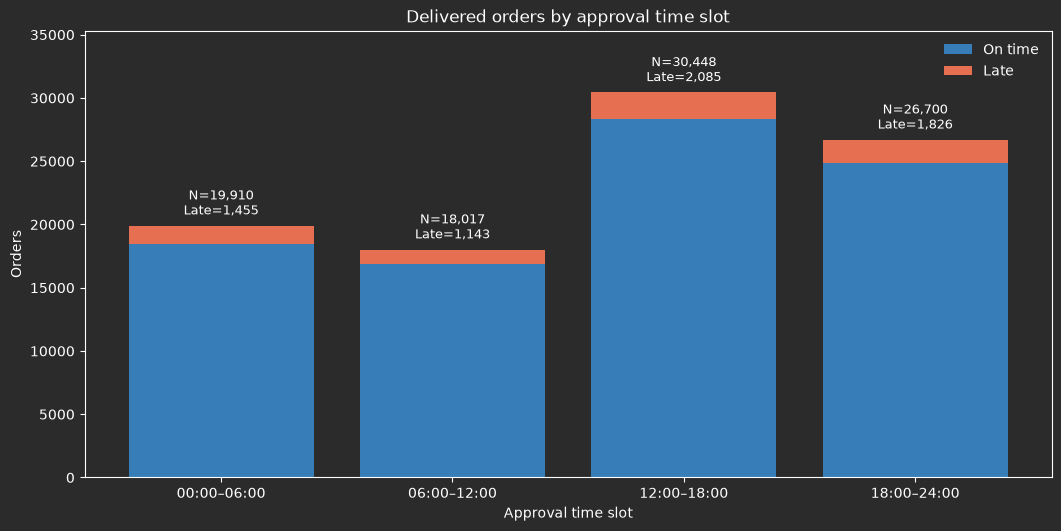

In [7]:
slot_counts_figure = plot_slot_counts(slot_summary)
display(slot_counts_figure)
plt.close(slot_counts_figure)


The 12:00–18:00 slot has both the largest order volume and the most late orders. Its late rate remains close to the overall rate, as shown in the summary table.


### Late rate by approval hour

Counts above each bar show the denominator behind its rate. An hour with few orders needs more caution when comparing rates.


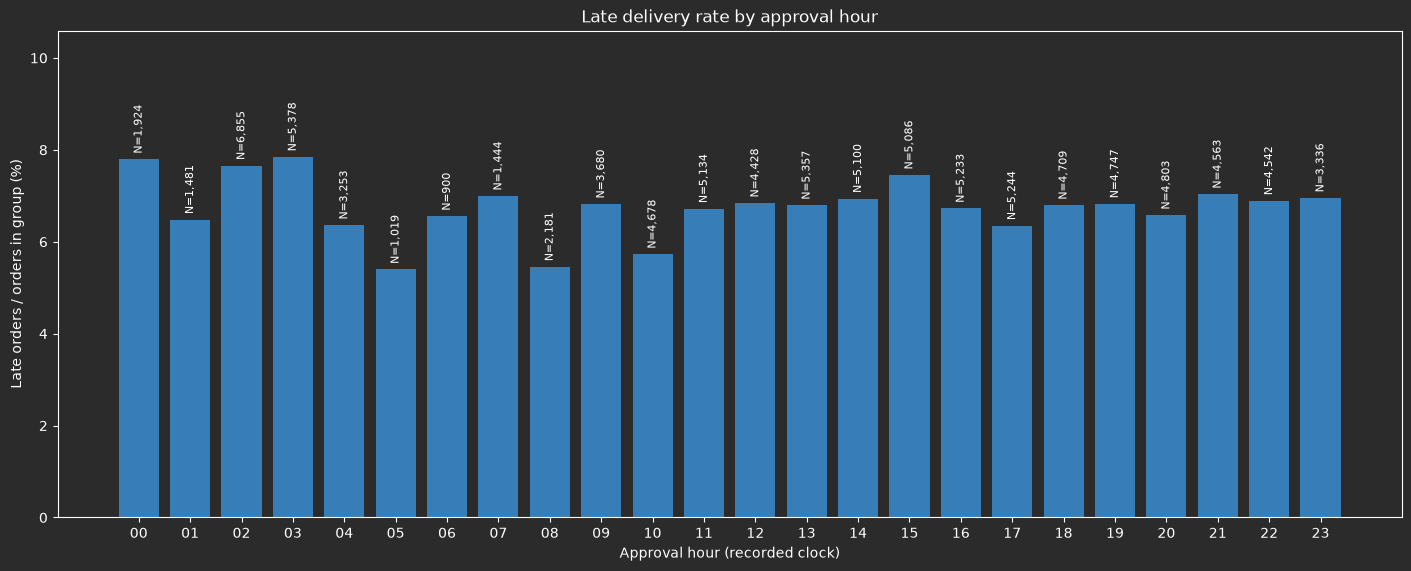

In [8]:
hourly_rate_figure = plot_rate_profile(temporal_profiles["hours"], "approval_hour")
display(hourly_rate_figure)
plt.close(hourly_rate_figure)


Among individual hours, 03:00–03:59 has the highest observed late rate (7.85%, 422 of 5,378 orders). The busiest approval hour is 02:00–02:59, with 6,855 orders and a 7.66% late rate.


### Late rate by approval weekday

Each bar uses all analyzable orders approved on that weekday.


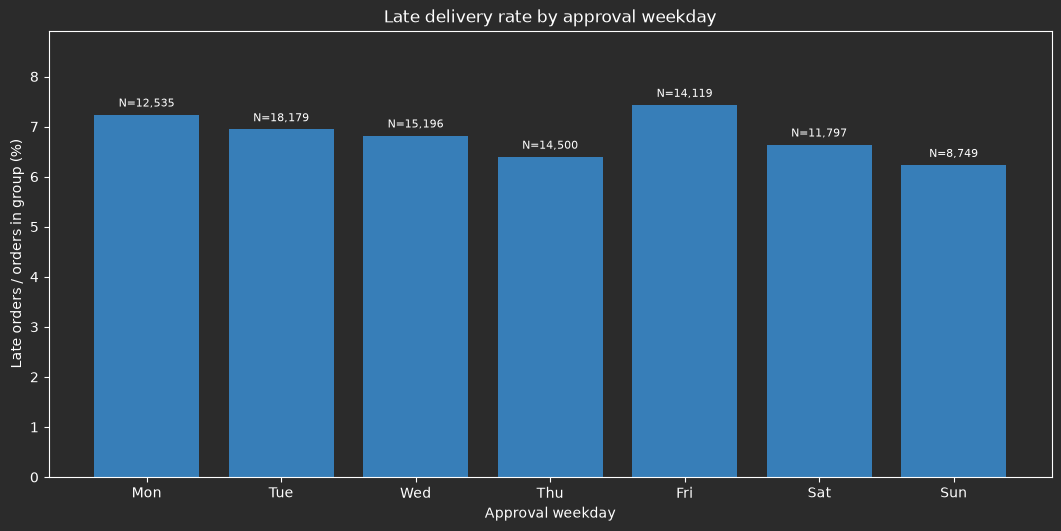

In [9]:
weekday_rate_figure = plot_rate_profile(temporal_profiles["weekdays"], "approval_weekday")
display(weekday_rate_figure)
plt.close(weekday_rate_figure)


Friday has the highest observed weekday late rate (7.43%, 1,049 of 14,119 orders). This comparison uses the full weekday group, independent of approval hour.


### Approval hour by weekday

The upper heatmap shows late rates and the lower heatmap shows order counts for the same cells. Grey cells have no orders; their late rate is undefined. The table beneath the figure lists the ten highest observed cell rates with their order counts.


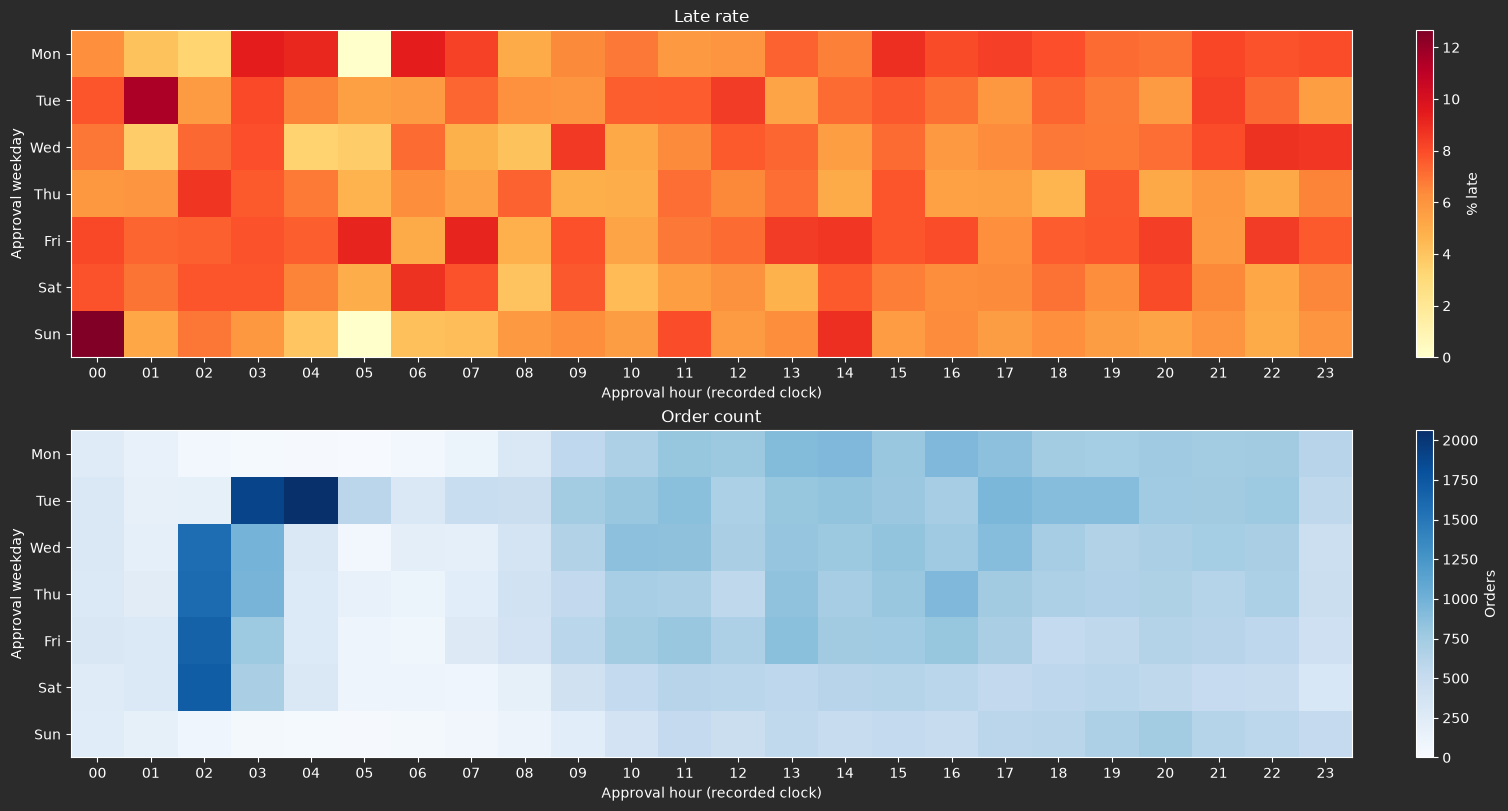

Weekday (Mon=0),Approval hour,Orders,Late orders,Late rate (%)
6,0,237,30,12.66
1,1,166,19,11.45
0,6,64,6,9.38
0,3,32,3,9.38
4,7,272,25,9.19
4,5,98,9,9.18
0,4,22,2,9.09
6,14,498,44,8.84
0,15,794,70,8.82
5,6,103,9,8.74


In [10]:
hour_weekday_figure = plot_hour_weekday_heatmap(temporal_profiles["hour_weekday"])
display(hour_weekday_figure)
plt.close(hour_weekday_figure)
display(
    temporal_profiles["hour_weekday"].sort_values("late_rate_pct", ascending=False)
    .head(10).rename(columns={
        "approval_weekday": "Weekday (Mon=0)",
        "approval_hour": "Approval hour",
        "orders": "Orders",
        "late_orders": "Late orders",
        "late_rate_pct": "Late rate (%)",
    }).style.format({"Late rate (%)": "{:.2f}", "Orders": "{:,.0f}", "Late orders": "{:,.0f}"})
    .hide(axis="index")
)


The highest observed hour-by-weekday rate is Sunday 00:00–00:59, at 12.66% (30 of 237 orders). The paired count panel shows why a high-rate cell should be read alongside its sample size.


### Delay duration among late orders

Both panels use only late orders. The first retains the full range. The second zooms to the 99th percentile for readability; observations outside the view remain in the data.


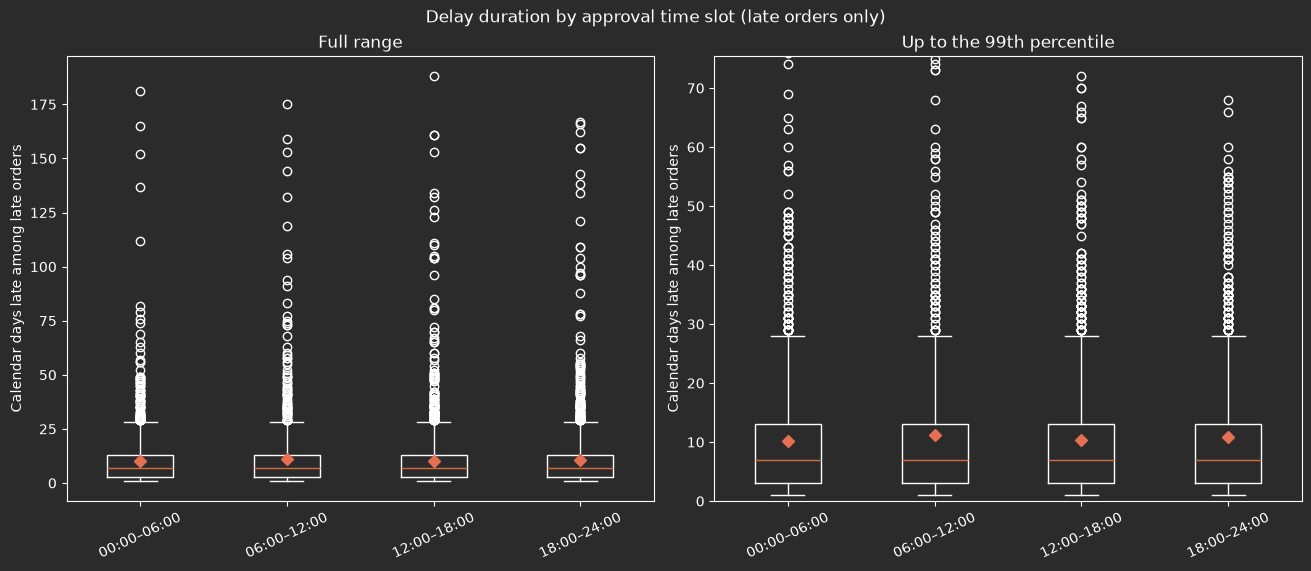

In [11]:
delay_distribution_figure = plot_delay_distribution(orders)
display(delay_distribution_figure)
plt.close(delay_distribution_figure)


Every approval slot has a median delay of seven days among late orders. The means differ more, so the upper tail contributes to the severity ranking.


<a id="analysis-statistics" name="analysis-statistics"></a>

## 5. Statistical comparison of slots

The Chi-square test evaluates whether late-delivery rates differ across the four approval slots. The null hypothesis is that all four rates are equal. The alternative is that at least one rate differs. The significance level is 5%.


### Observed counts and expected frequencies

The observed table counts on-time and late orders within each slot. Expected counts represent the distribution under equal late rates. All four slots and both outcomes must have observations, and each expected count must be at least five for the approximation used here.


In [12]:
slot_test = test_slot_association(slot_summary, alpha=0.05)

print("Observed order counts")
display(slot_test["observed"].rename(columns={
    "on_time_orders": "On time", "late_orders": "Late",
}))
print("Expected counts under equal late rates")
display(slot_test["expected"].rename(columns={
    "on_time_orders": "On time", "late_orders": "Late",
}).style.format("{:,.2f}", na_rep="—"))
display(slot_test["checks"])
assert slot_test["observed"].to_numpy().sum() == len(orders)
assert slot_test["observed"]["late_orders"].sum() == orders["is_late"].sum()


Observed order counts


,On time,Late
approval_slot,,
00:00–06:00,18455,1455
06:00–12:00,16874,1143
12:00–18:00,28363,2085
18:00–24:00,24874,1826


Expected counts under equal late rates


,On time,Late
approval_slot,,
00:00–06:00,"18,546.93","1,363.07"
06:00–12:00,"16,783.52","1,233.48"
12:00–18:00,"28,363.48","2,084.52"
18:00–24:00,"24,872.07","1,827.93"


,check,passed
0,At least one analyzable order,True
1,All four slots have orders,True
2,Both delivery outcomes are present,True
3,Every expected count is at least five,True


### Test result and size of the association

The p-value measures how unusual the overall difference would be under equal rates and the test assumptions. Cramer's V describes the strength of association. The percentage-point gap compares the highest and lowest observed rates.


In [13]:
test_result = slot_test["result"].iloc[0]
test_metrics = slot_test["result"][[
    "orders", "alpha", "chi2", "dof", "p_value",
    "min_expected", "cramers_v", "rate_range_pp",
]].rename(columns={
    "orders": "Analyzable orders",
    "alpha": "Significance threshold",
    "chi2": "Chi-square statistic",
    "dof": "Degrees of freedom",
    "p_value": "P-value",
    "min_expected": "Smallest expected count",
    "cramers_v": "Cramér's V",
    "rate_range_pp": "Highest minus lowest rate (percentage points)",
}).T
test_metrics.columns = ["Value"]
display(test_metrics.style.format("{:,.6g}", na_rep="—"))
print(test_result["decision"])


,Value
Analyzable orders,"95,075"
Significance threshold,0.05
Chi-square statistic,13.7816
Degrees of freedom,3
P-value,0.00321801
Smallest expected count,"1,233.48"
Cramér's V,0.0120397
Highest minus lowest rate (percentage points),0.963877


Reject equal rates


Late-delivery rates differ across approval slots in the analyzed cohort, with Chi-square = 13.78, 3 degrees of freedom and p = 0.0032. The minimum expected count is 1,233, satisfying the frequency criterion.

The largest observed rate difference is 0.96 percentage points, and Cramer's V is 0.012. This indicates a small association. The large sample provides evidence of a difference even though its absolute size is modest.


### Interpretation limits

The Chi-square p-value applies to the four-slot table as a whole. The slot rankings describe observed rates; the overall test does not establish which individual pairs differ.

Orders sharing an approval date or seller may be exposed to common operating conditions, which can violate the independence assumption. The p-value therefore depends on an assumption that cannot be fully verified from these records.

The findings apply to delivered orders retained after cleaning. Differences in season, geography or promised delivery time may also contribute to the observed association. The results alone do not establish the effect of changing warehouse or carrier schedules.
